<img src="https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main/mse_logo.png" width="400" align="right"/>
<div style="text-align: left"> <b> Machine Learning FTP_MachLe </b> <br> HS 2026 <br> <a href="mailto:christoph.wuersch@ost.ch"> Christoph Würsch </a> </div>

In [1]:
# imports
from IPython.display import Image, display
from IPython.display import HTML
import os
import requests
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# allow plots to appear directly in the notebook
%matplotlib inline

# raw URL of this repository on GitHub (images, data)
filepath = "https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main"

# **Feature Engineering – Group 5: Feature Selection II**

**Authors:** *Marco Kleimaier, Romain Nykyforchyn, Davide Zepponi, Eric Lindegger, David Matías Silva, Dario Francesco Bralla Mattia, Robin Roth,  Leander Hildebrandt*

### Instructor review (2026-10-08)

This notebook (Group 5 – Feature Selection II) was checked against the group-work assignment. Changes are marked directly in the notebook:

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> <span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> <span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> <span style="background-color:#e2e3e5;color:#383d41;padding:2px 8px;border-radius:4px;font-weight:bold">[REMOVED]</span>

Code changes are marked with a comment `# [ADDED]`, `# [CORRECTED]`, ... All changed cells also carry a cell tag `review-*`.

**Added**
- (ii) Visualization of the $L_1$ diamond vs. $L_2$ circle with RSS contours and solution paths for a two-feature regression (replaces the Lasso theory)
- (ii) Practical notes on the Lasso (standardization, LassoCV, correlated features → arbitrary pick, Elastic Net pointer) + small demo
- (iii) MDI definition, bias of impurity importances, permutation importance on held-out data, `SelectFromModel`; executable example (replaces the local image `importances.png`)
- (iv) `RFECV` and feature selection inside a CV pipeline, incl. leakage demo on pure noise
- Completed Takeaways; References section

**Corrected**
- (iii) `RandomForestClassifier` on a continuous target → `RandomForestRegressor`; top-10 plot logic
- (iv) RFE is greedy backward elimination, not an exhaustive search
- (iv) Scaler/RFE now in a pipeline; undefined `df_reduced` (NameError) fixed; long DataFrame printout removed

**Revised for clarity**
- (ii) Script docstring in the Lasso code replaced by a short comment
- (iv) Practical considerations (estimator needs `coef_`/`feature_importances_`)

**Removed (beyond course scope)**
- (ii) Detailed Lasso theory (formal definition, soft-thresholding, KKT conditions)

The empty template code cell under (ii) was dropped.


<img src="https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main/images/05_Feature_Selection_2.png" width="1200"/>

## Introduction

**What is it about?**
While univariate filters look at one feature at a time, *embedded* and *wrapper* methods select features **together with a model**. Regularization adds a penalty on the model coefficients; the $L_1$ penalty of the Lasso drives many coefficients exactly to zero and therefore performs feature selection automatically. Tree ensembles such as random forests provide feature importances that can be used for model-based selection. Recursive Feature Elimination (RFE) repeatedly fits a model, removes the least important feature(s), and refits until the desired number of features remains.

**Where is it used?**
In high-dimensional regression and classification problems (genomics, finance, process engineering, marketing), whenever a sparse and interpretable model is desired, and for building compact models that are cheaper to deploy. In scikit-learn: `Lasso`, `LassoCV`, `SelectFromModel`, `RandomForestRegressor/Classifier.feature_importances_`, `RFE` and `RFECV`.

**Why is it important for Machine Learning?**
Model-based methods take feature interactions and the actual learner into account and therefore often select better subsets than univariate filters. They reduce overfitting, improve interpretability ("which inputs really drive the prediction?") and lower the cost of data collection. At the same time, they require care: correlated features can make selections unstable, and the selection must be done inside cross-validation to avoid optimistic performance estimates.

## (i) Regularization as feature selection

Regularization controls **model complexity** by penalizing the weights $\theta_j$ of a linear model:

$$\mathcal{L}(\theta)=\mathrm{MSE}+\lambda\cdot\text{penalty on the weights}.$$

$\lambda$ controls model complexity. A larger $\lambda$ penalizes large weights more strongly. The tradeoff is generally **increased bias and decreased variance**, which can help avoid overfitting.

- **Ridge regression (L2 regularization):** penalizes squared weights, $\sum_{j=1}^{p}\theta_j^2$. It shrinks weights, but usually keeps them nonzero.
- **Lasso regression (L1 regularization):** penalizes absolute weights, $\sum_{j=1}^{p}|\theta_j|$. It can set weights **exactly to zero**, removing those features from the model.

Here, $p$ is the number of features; the intercept $\theta_0$ is not penalized.

**Example:** only `x1` and `x2` affect the target; the other three features are noise. We standardize the inputs and compare their weights.

In [2]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.preprocessing import StandardScaler

# create artificial dataset with 5 features and 200 rows
rng = np.random.default_rng(42)
X = rng.normal(size=(200, 5))

# for the artifical dataset, we make it so that x1 influences y with weight +4 and x2 with -3
# x3, x4 and x5 are noise
y = 4 * X[:, 0] - 3 * X[:, 1] + rng.normal(size=200)

# standardize so that each feature is treated fairly
X = StandardScaler().fit_transform(X)

# before: linear regression -> loss = MSE
before = LinearRegression().fit(X, y)
# lasso: L1 regularization -> some weights become zero
lambda_lasso = 0.4  # lambda controls the model complexity
lasso = Lasso(alpha=lambda_lasso / 2).fit(X, y)  # sklearn uses MSE / 2
# comparison: L2 regularization -> weights shrink, but usually stay nonzero
lambda_ridge = 0.1
ridge = Ridge(alpha=len(y) * lambda_ridge).fit(X, y)  # sklearn uses sum of squared errors

table = pd.DataFrame({
    "Feature": ["x1", "x2", "x3", "x4", "x5"],
    "Before (no penalty)": before.coef_,
    "After (Lasso)": lasso.coef_,
    "After (Ridge)": ridge.coef_,
    "Selected by Lasso": np.abs(lasso.coef_) > 1e-8,
})
display(table.round(3))

,Feature,Before (no penalty),After (Lasso),After (Ridge),Selected by Lasso
0,x1,3.919,3.702,3.525,True
1,x2,-2.676,-2.460,-2.384,True
2,x3,-0.031,-0.000,-0.061,False
3,x4,0.055,0.000,0.064,False
4,x5,-0.064,-0.000,-0.118,False


**Result:** Lasso sets the weights $\theta_3$, $\theta_4$, and $\theta_5$ to zero and keeps only `x1` and `x2`. Ridge reduces the large weights but keeps all five features. L1 regularization therefore performs feature selection, while L2 regularization mainly shrinks weights. The values of $\lambda$ are chosen for illustration. In practice, choose them using cross-validation.


## (ii) Lasso regression



<span style="background-color:#e2e3e5;color:#383d41;padding:2px 8px;border-radius:4px;font-weight:bold">[REMOVED]</span>

*The detailed Lasso theory (formal definition, soft-thresholding for orthonormal designs, subgradient/KKT conditions)* was removed: too detailed for the course; replaced by the geometric visualization of the $L_1$ diamond and $L_2$ circle below.

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

### Lasso in one line – and why it sets coefficients to zero

The **Lasso** is linear regression with an $L_1$ penalty, **Ridge** uses an $L_2$ penalty:

$$
\hat\beta^{\text{Lasso}} = \arg\min_\beta \;\lVert y - X\beta\rVert_2^2 + \lambda \sum_j |\beta_j|,
\qquad
\hat\beta^{\text{Ridge}} = \arg\min_\beta \;\lVert y - X\beta\rVert_2^2 + \lambda \sum_j \beta_j^2 .
$$

(scikit-learn calls $\lambda$ `alpha` and scales the RSS by $\tfrac{1}{2n}$ – this only rescales $\lambda$.)

Each penalized problem is equivalent to minimizing the RSS **inside a budget region**:
$|\beta_1| + |\beta_2| \le t$ (a **diamond**) for the Lasso, $\beta_1^2 + \beta_2^2 \le t^2$ (a **circle**) for Ridge.
The RSS contours are ellipses centred at the OLS solution. The solution is the point where the
smallest ellipse **touches** the budget region. The plot below shows this for a regression with two
standardized, correlated features ($y = 2x_1 + 0.5x_2 + \varepsilon$); the dashed red line is the
solution path when the penalty grows from 0 (OLS) to ∞ (all coefficients 0).

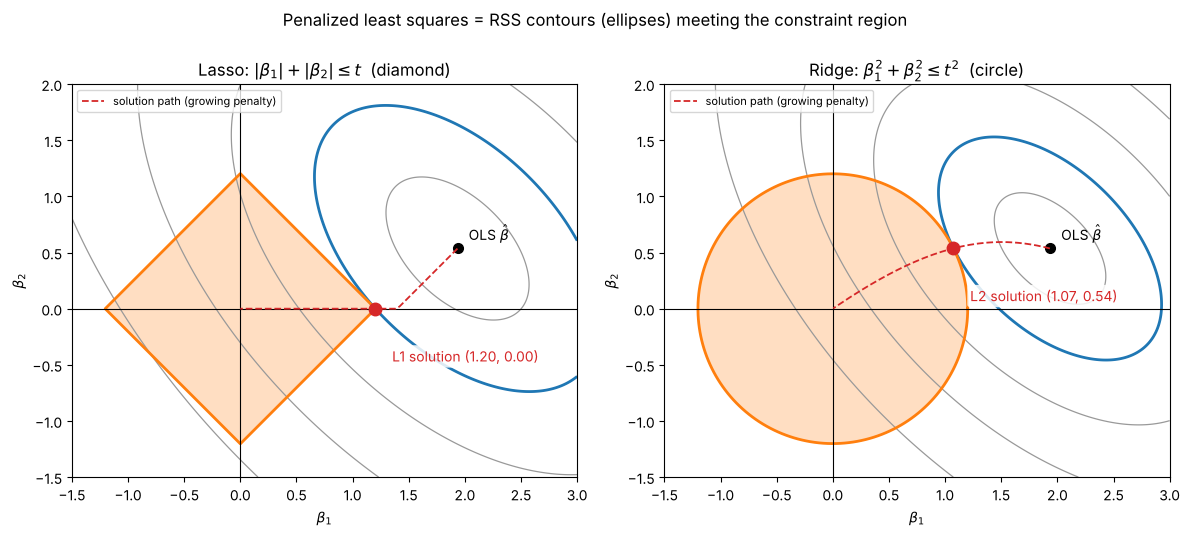

OLS [1.935 0.536]  Lasso [1.204 0.   ]  Ridge [1.074 0.538]


In [3]:
# [ADDED]
# Geometry of Lasso (L1) vs. Ridge (L2) for a regression with two features
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso, Ridge, LinearRegression

# Two standardized, correlated features; only x1 really matters
rng = np.random.default_rng(42)
n = 200
x1 = rng.normal(size=n)
x2 = 0.6 * x1 + 0.8 * rng.normal(size=n)          # corr(x1, x2) ≈ 0.6
X = np.column_stack([x1, x2])
X = (X - X.mean(0)) / X.std(0)
y = 2.0 * X[:, 0] + 0.5 * X[:, 1] + rng.normal(scale=1.0, size=n)
y = y - y.mean()                                    # centered -> no intercept needed

b_ols = LinearRegression(fit_intercept=False).fit(X, y).coef_
b_l1 = Lasso(alpha=1.0, fit_intercept=False).fit(X, y).coef_
b_l2 = Ridge(alpha=160, fit_intercept=False).fit(X, y).coef_

# RSS on a grid of (beta1, beta2)
g1, g2 = np.meshgrid(np.linspace(-1.5, 3.0, 400), np.linspace(-1.5, 2.0, 400))
B = np.stack([g1.ravel(), g2.ravel()], axis=1)
rss = (((y[:, None] - X @ B.T) ** 2).sum(0)).reshape(g1.shape)
rss_fn = lambda b: np.sum((y - X @ b) ** 2)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, b, kind in [(axes[0], b_l1, "L1"), (axes[1], b_l2, "L2")]:
    levels = rss_fn(b_ols) + np.array([0.25, 1, 2.5, 5, 9]) * (rss_fn(b) - rss_fn(b_ols))
    ax.contour(g1, g2, rss, levels=np.sort(levels), colors="0.6", linewidths=0.9)
    ax.contour(g1, g2, rss, levels=[rss_fn(b)], colors="tab:blue", linewidths=2)   # contour touching the region
    if kind == "L1":
        t = np.abs(b).sum()                                         # budget  |b1| + |b2| <= t
        region = np.array([[t, 0], [0, t], [-t, 0], [0, -t], [t, 0]])
        title = r"Lasso: $|\beta_1| + |\beta_2| \leq t$  (diamond)"
    else:
        t = np.linalg.norm(b)                                       # budget  b1^2 + b2^2 <= t^2
        phi = np.linspace(0, 2 * np.pi, 200)
        region = np.column_stack([t * np.cos(phi), t * np.sin(phi)])
        title = r"Ridge: $\beta_1^2 + \beta_2^2 \leq t^2$  (circle)"
    ax.fill(region[:, 0], region[:, 1], color="tab:orange", alpha=0.25)
    ax.plot(region[:, 0], region[:, 1], color="tab:orange", lw=2)
    ax.axhline(0, color="k", lw=0.8); ax.axvline(0, color="k", lw=0.8)
    ax.plot(*b_ols, "ko", ms=7)
    ax.annotate(r"OLS $\hat\beta$", b_ols, xytext=(8, 6), textcoords="offset points")
    # solution path for all penalty strengths (from OLS towards 0)
    alphas = np.logspace(-3, 0.5, 150) if kind == "L1" else np.logspace(-1, 5, 150)
    model = Lasso if kind == "L1" else Ridge
    path = np.array([model(alpha=a, fit_intercept=False).fit(X, y).coef_ for a in alphas])
    ax.plot(path[:, 0], path[:, 1], "--", color="tab:red", lw=1.3, label="solution path (growing penalty)")
    ax.plot(*b, "o", color="tab:red", ms=9, zorder=5)
    ax.annotate(f"{kind} solution ({b[0]:.2f}, {b[1]:.2f})", b, xytext=(12, -38),
                textcoords="offset points", color="tab:red",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
    ax.legend(loc="upper left", fontsize=8)
    ax.set_xlabel(r"$\beta_1$"); ax.set_ylabel(r"$\beta_2$")
    ax.set_title(title); ax.set_aspect("equal")
    ax.set_xlim(-1.5, 3.0); ax.set_ylim(-1.5, 2.0)
fig.suptitle("Penalized least squares = RSS contours (ellipses) meeting the constraint region", y=1.0)
fig.tight_layout()
plt.show()
print("OLS", b_ols.round(3), " Lasso", b_l1.round(3), " Ridge", b_l2.round(3))

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**Reading the plot.**
- **Diamond (L1):** the ellipse touches the diamond at a **corner on the $\beta_1$-axis**, so $\hat\beta_2 = 0$
  exactly – feature $x_2$ is removed. The corners of the diamond lie on the axes, and for most data the
  ellipses hit a corner (or edge) first. The solution path runs along the axis: once a coefficient is zero,
  it stays zero over a whole range of $\lambda$ → **feature selection**.
- **Circle (L2):** the circle has no corners; the tangent point lies **off the axes**, here
  $\hat\beta \approx (1.07, 0.54)$. Ridge shrinks both coefficients towards 0 but only reaches 0 for
  $\lambda \to \infty$ → **shrinkage, no selection**.
- In $p$ dimensions the diamond becomes a cross-polytope with even more corners and edges on the
  coordinate (sub)spaces, so the Lasso typically sets *many* coefficients to zero.

True coefficients: [ 5. -3.  2.  0.  0.  0.  0.  0.  0.  0.]

  OLS (no penalty): 0 of 10 coefficients are exactly 0
    [ 4.78e+00 -3.04e+00  1.96e+00 -2.20e-02 -2.83e-04 -4.63e-02 -3.50e-02
  3.95e-02  3.57e-03  5.47e-02]

        Ridge (L2): 0 of 10 coefficients are exactly 0
    [ 4.73e+00 -3.00e+00  1.93e+00 -2.01e-02 -4.41e-03 -4.63e-02 -3.86e-02
  4.72e-02  3.90e-03  4.34e-02]

        Lasso (L1): 7 of 10 coefficients are exactly 0
    [ 4.19 -2.41  1.33  0.   -0.    0.   -0.    0.   -0.   -0.  ]

LassoCV chose alpha = 0.044

           LassoCV: 7 of 10 coefficients are exactly 0
    [ 4.74 -2.96  1.91 -0.    0.   -0.   -0.    0.   -0.    0.  ]


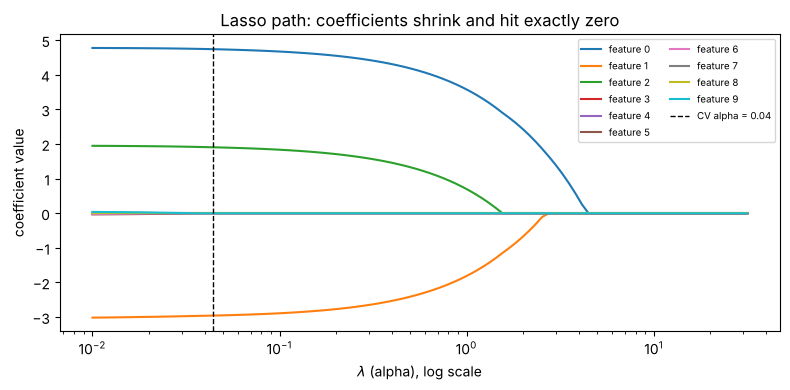

In [4]:
# [REVISED] script docstring ('Run: python lasso.py') replaced by a short comment
# Lasso as feature selection: 10 features, only 3 are relevant.
# Compare OLS, Ridge (L2) and Lasso (L1) coefficients, then choose alpha by CV.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LassoCV

# ----------------------------------------------------------------------
# 1. Make a controlled dataset: 10 features, only 3 are truly relevant
# ----------------------------------------------------------------------
rng = np.random.default_rng(0)
n_samples, n_features = 100, 10
true_beta = np.zeros(n_features)
true_beta[:3] = [5.0, -3.0, 2.0]          # only features 0,1,2 matter

X = rng.normal(size=(n_samples, n_features))
y = X @ true_beta + rng.normal(scale=0.5, size=n_samples)   # linear + noise

# Standardize (L1/L2 penalties depend on the scale of the coefficients)
X = (X - X.mean(axis=0)) / X.std(axis=0)

# ----------------------------------------------------------------------
# 2. Fit OLS, Ridge and Lasso
# ----------------------------------------------------------------------
ols = LinearRegression().fit(X, y)
ridge = Ridge(alpha=1.0).fit(X, y)
lasso = Lasso(alpha=0.5).fit(X, y)


def show(name, coef):
    """Print coefficients, marking exact zeros, and count selected features."""
    zeros = np.sum(np.isclose(coef, 0.0))
    print(f"\n{name:>18}: {zeros} of {len(coef)} coefficients are exactly 0")
    print("   ", np.array2string(coef, precision=2, suppress_small=False))


print("True coefficients:", true_beta)
show("OLS (no penalty)", ols.coef_)
show("Ridge (L2)", ridge.coef_)
show("Lasso (L1)", lasso.coef_)

# Expected: Ridge shrinks all 10 coefficients but zeroes none;
#           Lasso keeps the 3 relevant features and zeroes the other 7.

# ----------------------------------------------------------------------
# 3. Choose lambda(=alpha) by cross-validation and look at the effect
# ----------------------------------------------------------------------
lasso_cv = LassoCV(cv=5, random_state=0).fit(X, y)
print(f"\nLassoCV chose alpha = {lasso_cv.alpha_:.3f}")
show("LassoCV", lasso_cv.coef_)

# ----------------------------------------------------------------------
# 4. Regularization path: coefficients vs. alpha
# ----------------------------------------------------------------------
alphas = np.logspace(-2, 1.5, 100)
coefs = np.array([Lasso(alpha=a).fit(X, y).coef_ for a in alphas])

fig, ax = plt.subplots(figsize=(8, 4))
for j in range(n_features):
    ax.plot(alphas, coefs[:, j], label=f"feature {j}")
ax.axvline(lasso_cv.alpha_, color="k", ls="--", lw=1,
           label=f"CV alpha = {lasso_cv.alpha_:.2f}")
ax.set_xscale("log")
ax.set_xlabel(r"$\lambda$ (alpha), log scale")
ax.set_ylabel("coefficient value")
ax.set_title("Lasso path: coefficients shrink and hit exactly zero")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

# Takeaway: as lambda grows, coefficients leave the model one after another
# (they become exactly zero) -- that is feature selection in action.


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**Practical notes on the Lasso**

- **Standardize first** (inside a `Pipeline`, fitted on the training data only): the penalty
  $\lambda\sum_j|\beta_j|$ treats all coefficients equally, so a feature measured in large units
  (small $\beta_j$) would be penalized less than the same feature in small units.
- **Choose $\lambda$ by cross-validation** (`LassoCV`, see the cell above, dashed line in the path plot).
  The prediction-optimal $\lambda$ is often slightly too small for pure selection and may let a few
  noise features in; inspect the path or the stability of the selection across folds.
- **Correlated features:** if two features carry (almost) the same information, the Lasso typically keeps
  **one of them and drops the other — which one is essentially arbitrary** (it depends on tiny
  differences in the data or even the column order). A zero coefficient therefore does *not* mean
  "irrelevant". The **Elastic Net** ($L_1 + L_2$ penalty, `ElasticNet`) keeps groups of correlated features together.

In [5]:
# [ADDED]
# Lasso with two (almost) identical features: one is kept, the other is dropped
rng = np.random.default_rng(1)
n = 200
a = rng.normal(size=n)
b = a + 0.01 * rng.normal(size=n)          # b is practically a copy of a
c = rng.normal(size=n)
y_corr = 3 * a + 3 * b + c + rng.normal(size=n)

X_ab = StandardScaler().fit_transform(np.c_[a, b, c])
X_ba = X_ab[:, [1, 0, 2]]                   # same data, columns a and b swapped

coef_ab = Lasso(alpha=0.1).fit(X_ab, y_corr).coef_
coef_ba = Lasso(alpha=0.1).fit(X_ba, y_corr).coef_[[1, 0, 2]]   # reorder back to (a, b, c)

from sklearn.linear_model import ElasticNet
coef_en = ElasticNet(alpha=0.1, l1_ratio=0.5).fit(X_ab, y_corr).coef_

display(pd.DataFrame({"Lasso, order (a,b,c)": coef_ab,
                      "Lasso, order (b,a,c)": coef_ba,
                      "Elastic Net": coef_en},
                     index=["a", "b (≈ a)", "c"]).round(2))

,"Lasso, order (a,b,c)","Lasso, order (b,a,c)",Elastic Net
a,5.35,0.00,2.64
b (≈ a),0.00,5.35,2.64
c,0.93,0.94,0.95


## (iii) Model-based feature selection (random forest)



<span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> *the code used RandomForestClassifier on the continuous diabetes target (must be RandomForestRegressor), plotted head(10) instead of the top features and referenced a local image (importances.png) that is not part of the notebook; code moved to an executable cell below. MDI definition, its biases, permutation importance and SelectFromModel added.*

**Main concept.** Train a model and let the model decide which features are relevant
(*embedded* selection). Any estimator that exposes `coef_` (e.g. Lasso, $L_1$-logistic regression)
or `feature_importances_` (tree ensembles) can be used with `SelectFromModel`, which keeps all
features whose importance exceeds a `threshold` (e.g. `"mean"`, `"median"`, or a number) or the
`max_features` most important ones.

#### Random forest feature importance (mean decrease in impurity, MDI)
A random forest is an ensemble of $T$ decision trees trained on bootstrap samples with random feature
subsets. Every split at node $t$ on feature $j$ reduces the impurity $I$ (variance/MSE for regression,
Gini or entropy for classification). The impurity-based importance sums these reductions, weighted by the
fraction of samples reaching the node, and averages over the trees:

$$
\mathrm{MDI}_j = \frac{1}{T}\sum_{\text{trees}}\;\sum_{t\,:\,\text{split on } j} \frac{N_t}{N}\Bigl(I(t) - \tfrac{N_{t_L}}{N_t}I(t_L) - \tfrac{N_{t_R}}{N_t}I(t_R)\Bigr),
$$

normalized so that $\sum_j \mathrm{MDI}_j = 1$ (`feature_importances_`). The most important features are then selected.

#### When to use random forest feature selection?
- many features and we need to narrow them down, without assuming a linear relationship
- nonlinear relations and feature interactions (e.g. age × income) — a linear Lasso would miss these
- works for classification (`RandomForestClassifier`) and regression (`RandomForestRegressor`);
  no scaling needed

#### Caveats (when *not* to trust MDI blindly)
- **Bias toward continuous / high-cardinality features:** they offer many split points and can reduce the
  (training-set) impurity even if they are pure noise; binary or low-cardinality features are under-rated.
- **Correlated features share (split) their importance:** each tree uses one or the other, so both look less
  important than the information they carry together — and dropping both can hurt.
- MDI is computed on the training data; with small datasets the scores are unstable.
- **Remedy: permutation importance on held-out data** (`sklearn.inspection.permutation_importance`):
  $\mathrm{PI}_j = s(\text{model}, X_\text{test}, y_\text{test}) - \overline{s(\text{model}, X_\text{test}^{(j\text{ permuted})}, y_\text{test})}$,
  i.e. how much the test score drops when feature $j$ is shuffled. It is model-agnostic and not biased
  toward high cardinality (correlated features still share importance).

**Example** (diabetes regression data + one added pure-noise feature `random_noise`):

Test R^2 = 0.270


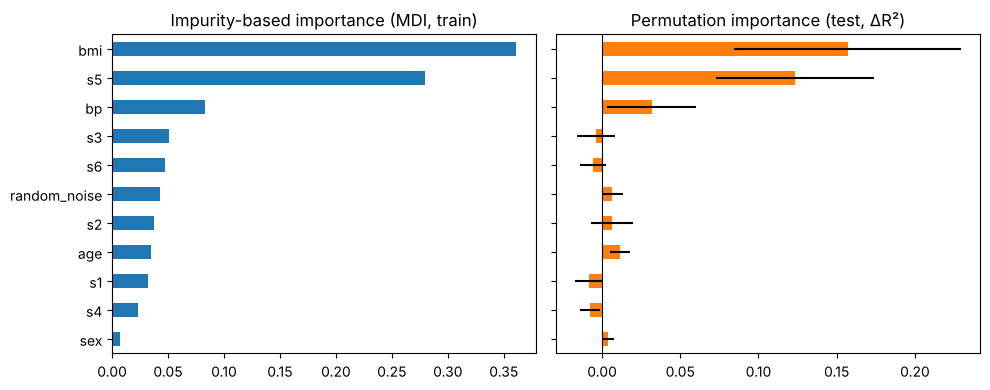

SelectFromModel (MDI > median) keeps: ['bmi', 'bp', 's3', 's5', 's6', 'random_noise']


In [6]:
# [ADDED]
from sklearn.datasets import load_diabetes
from sklearn.ensemble import RandomForestRegressor          # regression target -> Regressor
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import SelectFromModel

data = load_diabetes(as_frame=True)
X_db = data.data.copy()
X_db["random_noise"] = np.random.default_rng(0).normal(size=len(X_db))   # irrelevant by construction
y_db = data.target

X_train, X_test, y_train, y_test = train_test_split(X_db, y_db, test_size=0.25, random_state=0)

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1)
rf.fit(X_train, y_train)
print(f"Test R^2 = {rf.score(X_test, y_test):.3f}")

mdi = pd.Series(rf.feature_importances_, index=X_db.columns)                  # impurity-based (training data)
perm = permutation_importance(rf, X_test, y_test, n_repeats=20, random_state=0)  # held-out data
pi = pd.Series(perm.importances_mean, index=X_db.columns)
pi_std = pd.Series(perm.importances_std, index=X_db.columns)

order = mdi.sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
mdi[order].plot.barh(ax=axes[0], color="tab:blue")
axes[0].set_title("Impurity-based importance (MDI, train)")
pi[order].plot.barh(ax=axes[1], xerr=pi_std[order], color="tab:orange")
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_title("Permutation importance (test, ΔR²)")
fig.tight_layout()
plt.show()

# Model-based selection: keep features with MDI above the median importance
sfm = SelectFromModel(RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1),
                      threshold="median").fit(X_train, y_train)
print("SelectFromModel (MDI > median) keeps:", list(X_db.columns[sfm.get_support()]))

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**Interpretation.** Both importances agree that `bmi`, `s5` and `bp` dominate. However, MDI ranks the
pure-noise feature `random_noise` above several real features (and `SelectFromModel` with the median
threshold even keeps it), while the binary feature `sex` gets the lowest MDI. On held-out data the
permutation importance of `random_noise` is close to zero (within its error bar). Negative or near-zero
permutation importances indicate features the model does not need — or whose information is
also carried by correlated features (the blood-serum measures `s1`–`s6` are strongly correlated), so a
near-zero value is not proof of irrelevance.

## (iv) Recursive Feature Elimination (RFE)



<span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> *RFE is a greedy backward search, not an 'exhaustive search'; the claim that retraining captures interactions was qualified (only if the estimator models them).*

### What is Recursive Feature Elimination?

RFE (Guyon et al., 2002) is a **wrapper** method: a **greedy backward elimination** that uses the model's own
importance scores.

#### High-level algorithm
1. Initialize the set of features $F$ with all features.
2. While $|F|$ is greater than the target number of features (`n_features_to_select`):
    * fit the model on the features in $F$,
    * rank the features by importance (`|coef_|` or `feature_importances_`),
    * remove the `step` least important feature(s) from $F$.

#### Pros and cons

$+$
- The model is **refitted after each elimination**, so importances are re-evaluated in the context of the
  remaining features (e.g. when one of two correlated features is removed, the other one gains weight).
  This is better than ranking once and cutting. Interactions are only captured if the estimator itself
  models them (e.g. a random forest, not a linear model).
- Works with any estimator that provides `coef_` or `feature_importances_`.

$-$
- It is **greedy, not exhaustive**: a feature removed early is never reconsidered, so the optimal subset is
  not guaranteed (an exhaustive search over $2^p$ subsets is infeasible).
- A model has to be fitted in each iteration: about $(p - k)/\text{step}$ fits — expensive for large $p$
  or costly models (use `step > 1` or a fraction).
- The number of features $k$ must be chosen → `RFECV` (see below).

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *requirement coef_/feature_importances_ and pipeline remark added; stray bullet removed*

#### Practical considerations

* The estimator **must expose `coef_` or `feature_importances_`** (otherwise pass `importance_getter`).
* **Scale the features when using coefficient-based estimators**, because RFE ranks features by $|w_j|$,
  which is only comparable if all features are on the same scale:

  * large magnitude: strong influence on prediction
  * magnitude near zero: feature contributes little

> coefficient-based estimators:
>
> $y = w_1x_1 + w_2x_2 + \cdots + w_nx_n + b$
>
>  models that learn one numeric weight per feature, such as
> * Linear, Ridge or Lasso Regression, Logistic Regression
> * Linear SVMs

* Put scaler **and** RFE into a `Pipeline`, so that both are fitted on the training folds only.

### Simple Scikit Learn Example


In [7]:
# [CORRECTED] imported make_pipeline was unused (scaler fitted outside the selector); dataset made verifiable; full 500x20 DataFrame printout removed
from sklearn.datasets import make_classification
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# shuffle=False, n_redundant=0: the 5 informative features are columns 0-4, so we can check the result
X, y = make_classification(n_samples=500, n_features=20, n_informative=5, n_redundant=0,
                           shuffle=False, random_state=0)

# Scale first: coefficient magnitudes are only comparable on the same scale.
# Scaler + RFE in one pipeline -> both are fitted on the same (training) data only.
rfe_pipe = make_pipeline(
    StandardScaler(),
    RFE(estimator=LogisticRegression(max_iter=1000), n_features_to_select=5, step=1),
)
rfe_pipe.fit(X, y)
selector = rfe_pipe[-1]

print("Coefficients of the final model:", selector.estimator_.coef_.round(2))
print("Selected features (indices):   ", np.flatnonzero(selector.support_), " (truly informative: 0-4)")
print("Ranking: 1 = selected; higher = eliminated earlier")
print(selector.ranking_)

X_reduced = rfe_pipe.transform(X)
print("Reduced input matrix: from", X.shape, "to", X_reduced.shape)

Coefficients of the final model: [[ 1.05 -2.45 -0.52 -0.52 -0.86]]
Selected features (indices):    [0 1 2 3 4]  (truly informative: 0-4)
Ranking: 1 = selected; higher = eliminated earlier
[ 1  1  1  1  1  8 12  4  6 10  5  2  7  9  3 13 15 16 14 11]
Reduced input matrix: from (500, 20) to (500, 5)


In [8]:
# [CORRECTED] `df_reduced` was never defined (NameError)
# first rows of the reduced (scaled) input matrix
pd.DataFrame(X_reduced, columns=[f"x{j}" for j in np.flatnonzero(selector.support_)]).head()

,x0,x1,x2,x3,x4
0,-1.646989,1.564732,-1.368416,1.182582,-0.335675
1,0.406980,1.111740,-1.914633,1.839746,1.224628
2,0.383187,1.526133,-1.728310,-1.351771,2.733183
3,-0.814746,0.041696,1.211558,0.581871,-0.240385
4,-0.053259,-0.050793,-1.230405,1.539251,0.526056


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

### Choosing the number of features: `RFECV` — and selection inside cross-validation

`RFECV` runs RFE inside a cross-validation loop and picks the number of features $k$ with the best mean CV score
(`n_features_`, `cv_results_`).

**Leakage pitfall:** feature selection uses the target $y$. If features are selected on the *whole* dataset and
the model is evaluated afterwards by CV, the test folds have already influenced the selection → **optimistically
biased** scores (selection bias). The selection step must be part of the `Pipeline` that is cross-validated.
The second part of the cell shows this on **pure noise** (1000 random features, random labels — the true accuracy is 50 %).

In [9]:
# [ADDED]
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# 1) RFECV chooses k by cross-validation (same data as above)
rfecv_pipe = make_pipeline(StandardScaler(),
                           RFECV(LogisticRegression(max_iter=1000), step=1, cv=cv, scoring="accuracy"))
rfecv_pipe.fit(X, y)
print("RFECV: optimal number of features =", rfecv_pipe[-1].n_features_,
      "-> indices", np.flatnonzero(rfecv_pipe[-1].support_))

# 2) Leakage demo on pure noise: n=100 samples, p=1000 features, random labels
rng = np.random.default_rng(3)
X_noise = rng.normal(size=(100, 1000))
y_noise = rng.integers(0, 2, size=100)
rfe10 = RFE(LogisticRegression(max_iter=1000), n_features_to_select=10, step=0.2)

# WRONG: select on all data, then cross-validate the model on the selected features
X_sel = rfe10.fit(X_noise, y_noise).transform(X_noise)
acc_leaky = cross_val_score(LogisticRegression(max_iter=1000), X_sel, y_noise, cv=cv).mean()

# RIGHT: selection is refitted inside every training fold
acc_honest = cross_val_score(make_pipeline(rfe10, LogisticRegression(max_iter=1000)),
                             X_noise, y_noise, cv=cv).mean()
print(f"Pure noise - CV accuracy, selection outside CV: {acc_leaky:.2f}  (optimistic!)")
print(f"Pure noise - CV accuracy, selection inside CV:  {acc_honest:.2f}  (≈ chance level 0.5)")

RFECV: optimal number of features = 5 -> indices [0 1 2 3 4]
Pure noise - CV accuracy, selection outside CV: 0.74  (optimistic!)
Pure noise - CV accuracy, selection inside CV:  0.50  (≈ chance level 0.5)


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> *Takeaways were incomplete (third question unanswered, pitfalls missing); completed.*

## Takeaways

- **What should every ML practitioner remember?**
  - $L_1$ (Lasso) sets coefficients **exactly to zero** (corners of the $L_1$ diamond) → built-in feature
    selection; $L_2$ (Ridge) only shrinks.
  - **Standardize** before Lasso and before coefficient-based RFE; tree models need no scaling.
  - Tune the selection strength by CV: `LassoCV` for $\lambda$, `RFECV` for the number of features,
    `SelectFromModel(threshold=...)` for importance cut-offs.
  - Embedded methods (Lasso, random forest + `SelectFromModel`) are cheap; RFE (wrapper) is model-aware but
    needs many refits and is greedy.
- **What are common pitfalls?**
  - **Selecting features on the full dataset before CV/test split** → optimistic scores (see the noise demo:
    selection outside CV looks clearly better than chance, inside CV ≈ chance). Put scaler + selector + model in one `Pipeline`.
  - Forgetting to scale → the Lasso/RFE ranking reflects units, not relevance.
  - Interpreting the Lasso's choice among **correlated features** as meaningful — it is arbitrary
    (consider Elastic Net, check stability).
  - Trusting impurity-based RF importances: biased toward continuous/high-cardinality features, split among
    correlated ones → check with **permutation importance on held-out data**.
  - Using a classifier on a continuous target (e.g. `RandomForestClassifier` for regression).
- **When does this technique really matter?**
  - Many features relative to samples ($p \gtrsim n$, e.g. genomics, spectra, sensor arrays) and many
    irrelevant/noisy inputs, where a full model overfits.
  - When a **sparse, interpretable** or **cheap-to-deploy** model is required (fewer sensors/measurements).
  - Less critical for small $p$ or for strongly regularized nonlinear models (e.g. random forests), where
    selection mainly serves interpretability and cost rather than accuracy.

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> *References section was missing (empty cell).*

## References

1. R. Tibshirani (1996): Regression Shrinkage and Selection via the Lasso. *JRSS B* 58(1). https://doi.org/10.1111/j.2517-6161.1996.tb02080.x
2. A. E. Hoerl, R. W. Kennard (1970): Ridge Regression. *Technometrics* 12(1). https://doi.org/10.1080/00401706.1970.10488634
3. T. Hastie, R. Tibshirani, J. Friedman: *The Elements of Statistical Learning*, 2nd ed., Ch. 3.4 (Lasso/Ridge geometry). https://hastie.su.domains/ElemStatLearn/
4. H. Zou, T. Hastie (2005): Regularization and variable selection via the elastic net. *JRSS B* 67(2). https://doi.org/10.1111/j.1467-9868.2005.00503.x
5. L. Breiman (2001): Random Forests. *Machine Learning* 45. https://doi.org/10.1023/A:1010933404324
6. C. Strobl et al. (2007): Bias in random forest variable importance measures. *BMC Bioinformatics* 8:25. https://doi.org/10.1186/1471-2105-8-25
7. I. Guyon et al. (2002): Gene Selection for Cancer Classification using Support Vector Machines (RFE). *Machine Learning* 46. https://doi.org/10.1023/A:1012487302797
8. C. Ambroise, G. McLachlan (2002): Selection bias in gene extraction on the basis of microarray gene-expression data. *PNAS* 99(10). https://doi.org/10.1073/pnas.102102699
9. scikit-learn User Guide – Feature selection (`SelectFromModel`, `RFE`, `RFECV`): https://scikit-learn.org/stable/modules/feature_selection.html
10. scikit-learn User Guide – Linear models (Lasso, `LassoCV`, Elastic Net): https://scikit-learn.org/stable/modules/linear_model.html
11. scikit-learn – Permutation importance vs. random forest feature importance (MDI): https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance.html